# KMA/MSM – Přednáška 6: Testy o střední hodnotě

**Blanka Šedivá, KMA FAV ZČU Plzeň**

Notebook doprovází přednášku P06 a rozšiřuje původní notebook *Testy o poloze*. Pro každý test ukazujeme
výpočet „ručně“ podle vzorce ze slajdů, kontrolu knihovní funkcí a u vybraných testů i **simulaci**, která
ukazuje, co se stane při porušení předpokladů (navazuje na P03).

## Obsah

1. Jednorozměrná data – jeden výběr: z-test, t-test, Wilcoxonův a znaménkový test
2. Jednorozměrná data – dva výběry: t-test, Welchův test, F-test, Leveneův test, Mann-Whitneyův test a další
3. Párové testy
4. Vícerozměrná data – jeden výběr: test se známou $\Sigma$, Hotellingův $T^2$, test poměrem věrohodností, test o varianční matici
5. Vícerozměrná data – dva výběry: Hotellingův $T^2$, varianta pro různé $\Sigma_1,\Sigma_2$, test shody variančních matic
6. Shrnutí – jak vybrat test

**Značení:** $k$ je dimenze dat (počet proměnných), $S$ korigovaná výběrová varianční matice, $S_0=\frac{n-1}{n}S$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_iris

RNG = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
iris = load_iris(as_frame=True)
X_iris = iris.data.to_numpy()
y_iris = iris.target.to_numpy()
names = ['SL', 'SW', 'PL', 'PW']   # sepal/petal length/width

---
# 1. Jeden výběr

## 1.1 z-test (známý rozptyl)

$$Z=\frac{\bar X-\mu_0}{\sigma/\sqrt n}\sim N(0,1)\quad\text{za } H_0 .$$

In [2]:
x = np.array([5.3, 4.8, 5.6, 5.1, 5.4, 4.9, 5.7, 5.2])
mu_0, sigma = 5.0, 0.3          # sigma je znama
n = len(x)
z = (x.mean() - mu_0) / (sigma / np.sqrt(n))
print('Z = {:.3f}'.format(z))
print('p (oboustranný) = {:.4f}, p (pravostranný) = {:.4f}'.format(2 * stats.norm.sf(abs(z)), stats.norm.sf(z)))
print('kritická hodnota z_(alpha/2) = {:.3f}'.format(stats.norm.ppf(0.975)))

Z = 2.357
p (oboustranný) = 0.0184, p (pravostranný) = 0.0092
kritická hodnota z_(alpha/2) = 1.960


## 1.2 Jednovýběrový t-test (neznámý rozptyl)

Příklad z původního notebooku: testujeme $H_0:\mu=13$.
$$T=\frac{\bar X-\mu_0}{s/\sqrt n}\sim t_{n-1}.$$

In [3]:
data = np.array([12, 15, 14, 10, 13, 15, 14])
mu_0 = 13
n = len(data)
T = (data.mean() - mu_0) / (data.std(ddof=1) / np.sqrt(n))
p = 2 * stats.t.sf(abs(T), df=n - 1)
print('ručně:  T = {:.3f}, p = {:.3f}'.format(T, p))
print('scipy: ', stats.ttest_1samp(data, popmean=mu_0))

# interval spolehlivosti - test zamita H0 prave tehdy, kdyz mu_0 nelezi v intervalu
ci = stats.ttest_1samp(data, popmean=mu_0).confidence_interval(0.95)
print('95% interval spolehlivosti pro mu: ({:.2f}, {:.2f})'.format(ci.low, ci.high))

ručně:  T = 0.420, p = 0.689
scipy:  TtestResult(statistic=np.float64(0.42008402520840404), pvalue=np.float64(0.6890522264439646), df=np.int64(6))
95% interval spolehlivosti pro mu: (11.62, 14.95)


## 1.3 Wilcoxonův a znaménkový test

* **Wilcoxonův test** (předpoklad symetrie): $W^+=\sum_{D_i>0}R_i$, kde $R_i$ jsou pořadí $|D_i|$, $D_i=X_i-m_0$.
* **Znaménkový test**: počet kladných rozdílů $\sim Bi(n, 0{,}5)$ za $H_0$.

In [4]:
x = np.array([5.1, 4.9, 5.4, 5.2, 5.3, 5.6, 4.8, 5.5, 5.8, 5.25])
m_0 = 5.0
D = x - m_0
D = D[D != 0]                                  # nulove rozdily vynechame
R = stats.rankdata(np.abs(D))
W_plus = R[D > 0].sum()
nn = len(D)
EW, VW = nn * (nn + 1) / 4, nn * (nn + 1) * (2 * nn + 1) / 24
print('W+ = {}, normální aproximace: z = {:.3f}, p = {:.4f}'.format(
    W_plus, (W_plus - EW) / np.sqrt(VW), 2 * stats.norm.sf(abs(W_plus - EW) / np.sqrt(VW))))
print('scipy (přesná p-hodnota):', stats.wilcoxon(x - m_0))

kladne = int((D > 0).sum())
print('\nznaménkový test: {} kladných z {}'.format(kladne, nn), stats.binomtest(kladne, nn, 0.5))

W+ = 50.0, normální aproximace: z = 2.293, p = 0.0218
scipy (přesná p-hodnota): WilcoxonResult(statistic=np.float64(5.0), pvalue=np.float64(0.021484375))

znaménkový test: 8 kladných z 10 BinomTestResult(k=8, n=10, alternative='two-sided', statistic=0.8, pvalue=0.109375)


`scipy.stats.wilcoxon` vrací jako statistiku $\min(W^+,W^-)$ (zde $W^-=55-50=5$) a pro malé $n$ přesnou p-hodnotu; normální aproximace dává podobný výsledek. Znaménkový test stejná data nezamítne – je slabší, protože nevyužívá velikost odchylek.

## 1.4 Simulace: dodržuje t-test hladinu, když data nejsou normální?

Generujeme data ze silně zešikmeného exponenciálního rozdělení se střední hodnotou 1 a testujeme **platnou** hypotézu
$H_0:\mu=1$. Podíl zamítnutí by měl být blízko $\alpha=0{,}05$. Wilcoxonův test zde testuje **medián**
($\ln 2\ne 1$) – u nesymetrického rozdělení testuje jinou hypotézu, a proto „zamítá“ často.

In [5]:
B = 5000
rows = []
for n in [5, 10, 30, 100]:
    rej_t = rej_w = rej_s = 0
    for _ in range(B):
        x = RNG.exponential(1.0, n)
        rej_t += stats.ttest_1samp(x, 1.0).pvalue < 0.05
        rej_s += stats.binomtest(int((x > np.log(2)).sum()), n, 0.5).pvalue < 0.05   # H0: median = ln 2 (plati)
        rej_w += stats.wilcoxon(x - 1.0).pvalue < 0.05                               # H0: "median" = 1 (neplati!)
    rows.append({'n': n, 't-test (mu=1)': rej_t / B, 'znaménkový (median=ln2)': rej_s / B,
                 'Wilcoxon (m0=1)': rej_w / B})
display(pd.DataFrame(rows).set_index('n').round(3))

,t-test (mu=1),znaménkový (median=ln2),Wilcoxon (m0=1)
n,,,
5,0.118,0.000,0.000
10,0.105,0.022,0.094
30,0.077,0.036,0.171
100,0.062,0.035,0.380


* t-test na zešikmených datech pro malé $n$ hladinu nedodržuje přesně, s rostoucím $n$ se díky CLV zlepšuje.
* Znaménkový test drží hladinu (u diskrétního rozdělení statistiky je konzervativní).
* Wilcoxonův test zamítá s rostoucím $n$ stále častěji – nikoli chybou, ale proto, že u nesymetrického rozdělení
  netestuje hypotézu o střední hodnotě.

## 1.5 Simulace: síla testů

Posuneme střed rozdělení o $\delta$ a sledujeme podíl zamítnutí $H_0$ (síla testu) pro normální data a pro data
s těžkými chvosty (Studentovo $t_2$).

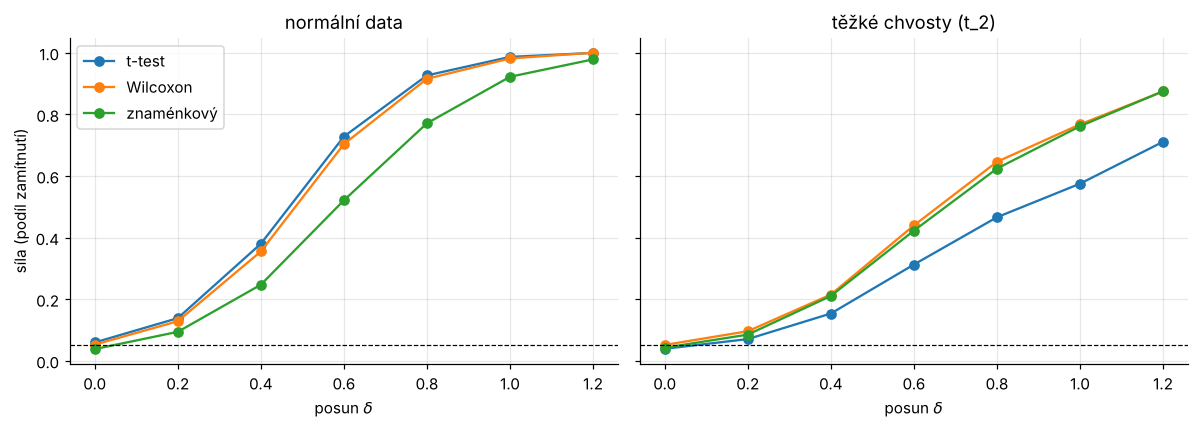

In [6]:
def power(gen, n=20, deltas=np.linspace(0, 1.2, 7), B=2000):
    out = {'t-test': [], 'Wilcoxon': [], 'znaménkový': []}
    for d in deltas:
        rt = rw = rs = 0
        for _ in range(B):
            x = gen(n) + d
            rt += stats.ttest_1samp(x, 0).pvalue < 0.05
            rw += stats.wilcoxon(x).pvalue < 0.05
            rs += stats.binomtest(int((x > 0).sum()), n, 0.5).pvalue < 0.05
        out['t-test'].append(rt / B); out['Wilcoxon'].append(rw / B); out['znaménkový'].append(rs / B)
    return deltas, out

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, (gen, title) in zip(axes, [(lambda n: RNG.normal(size=n), 'normální data'),
                                   (lambda n: RNG.standard_t(2, size=n), 'těžké chvosty (t_2)')]):
    deltas, out = power(gen)
    for name, v in out.items():
        ax.plot(deltas, v, 'o-', label=name)
    ax.axhline(0.05, color='k', lw=0.8, ls='--')
    ax.set_title(title); ax.set_xlabel(r'posun $\delta$')
axes[0].set_ylabel('síla (podíl zamítnutí)'); axes[0].legend()
plt.tight_layout(); plt.show()

Pro normální data je nejsilnější t-test, Wilcoxonův test ztrácí jen málo. Při těžkých chvostech je naopak
Wilcoxonův (i znaménkový) test výrazně silnější než t-test.

---
# 2. Dva nezávislé výběry

Data z původního notebooku a druhá dvojice výběrů s rozdílnými rozptyly a rozsahy.

In [7]:
group1 = np.array([10, 12, 11, 13, 12])
group2 = np.array([14, 15, 13, 16, 15])
n1, n2 = len(group1), len(group2)

# dvouvyberovy t-test "rucne"
sp = np.sqrt(((n1 - 1) * group1.var(ddof=1) + (n2 - 1) * group2.var(ddof=1)) / (n1 + n2 - 2))
T = (group1.mean() - group2.mean()) / (sp * np.sqrt(1 / n1 + 1 / n2))
print('ručně: T = {:.3f}, p = {:.4f}'.format(T, 2 * stats.t.sf(abs(T), n1 + n2 - 2)))
print('t-test (shodné rozptyly):', stats.ttest_ind(group1, group2, equal_var=True))
print('Welchův test:            ', stats.ttest_ind(group1, group2, equal_var=False))

ručně: T = -4.160, p = 0.0032
t-test (shodné rozptyly): TtestResult(statistic=np.float64(-4.160251471689219), pvalue=np.float64(0.003164123781235033), df=np.float64(8.0))
Welchův test:             TtestResult(statistic=np.float64(-4.160251471689218), pvalue=np.float64(0.0031641237812350394), df=np.float64(8.000000000000002))


## 2.1 Testy shody rozptylů

F-test předpokládá normalitu, Leveneův (střed = průměr) a Brown-Forsytheův (střed = medián) test jsou robustnější.

In [8]:
a = np.array([10, 12, 11, 13, 12])
b = np.array([14, 15, 13, 16, 15, 18, 11])
F = a.var(ddof=1) / b.var(ddof=1)
v1, v2 = len(a) - 1, len(b) - 1
p_F = 2 * min(stats.f.cdf(F, v1, v2), stats.f.sf(F, v1, v2))
print('F = {:.3f}, p = {:.4f}'.format(F, p_F))
print('Levene:         ', stats.levene(a, b, center='mean'))
print('Brown-Forsythe: ', stats.levene(a, b, center='median'))

F = 0.262, p = 0.2163
Levene:          LeveneResult(statistic=np.float64(1.3342486944489436), pvalue=np.float64(0.2749053742563383))
Brown-Forsythe:  LeveneResult(statistic=np.float64(1.0510380622837368), pvalue=np.float64(0.32942827683611864))


## 2.2 Simulace: klasický t-test vs. Welchův test při různých rozptylech

Obě skupiny mají stejnou střední hodnotu ($H_0$ platí), ale menší skupina má větší rozptyl. Klasický t-test
pak zamítá platnou hypotézu mnohem častěji, než by měl.

In [9]:
B = 5000
rows = []
for (n1, s1, n2, s2) in [(10, 1, 10, 1), (10, 3, 10, 1), (10, 3, 40, 1), (40, 3, 10, 1)]:
    r_pool = r_welch = 0
    for _ in range(B):
        x1, x2 = RNG.normal(0, s1, n1), RNG.normal(0, s2, n2)
        r_pool += stats.ttest_ind(x1, x2).pvalue < 0.05
        r_welch += stats.ttest_ind(x1, x2, equal_var=False).pvalue < 0.05
    rows.append({'n1': n1, 'sigma1': s1, 'n2': n2, 'sigma2': s2,
                 'klasický t-test': r_pool / B, 'Welchův test': r_welch / B})
display(pd.DataFrame(rows).round(3))

,n1,sigma1,n2,sigma2,klasický t-test,Welchův test
0,10,1,10,1,0.046,0.045
1,10,3,10,1,0.060,0.050
2,10,3,40,1,0.250,0.047
3,40,3,10,1,0.002,0.051


Pokud má **menší** skupina **větší** rozptyl, klasický t-test zamítá platnou $H_0$ zhruba ve 25 % případů místo 5 %. V opačném případě (větší skupina má větší rozptyl) je naopak příliš konzervativní a ztrácí sílu. Welchův test
hladinu drží ve všech případech – proto se doporučuje jako výchozí volba.

## 2.3 Neparametrické testy

Mann-Whitneyův test ($U=R_1-\frac{n_1(n_1+1)}2$), Brunnerův-Munzelův test, Kolmogorovův-Smirnovův test a permutační test
rozdílu průměrů.

In [10]:
a = np.array([10, 12, 11, 13, 12])
b = np.array([14, 15, 13, 16, 15, 18, 11])
R1 = stats.rankdata(np.r_[a, b])[:len(a)].sum()
U = R1 - len(a) * (len(a) + 1) / 2
print('U = {}'.format(U))
print('Mann-Whitney:   ', stats.mannwhitneyu(a, b, alternative='two-sided'))
print('Brunner-Munzel: ', stats.brunnermunzel(a, b))
print('Kolmogorov-Smirnov:', stats.ks_2samp(a, b))

perm = stats.permutation_test((a, b), lambda x, y: x.mean() - y.mean(),
                              permutation_type='independent', n_resamples=20000, random_state=0)
print('permutační test rozdílu průměrů: p = {:.4f}'.format(perm.pvalue))

U = 4.0
Mann-Whitney:    MannwhitneyuResult(statistic=np.float64(4.0), pvalue=np.float64(0.03349369017790239))
Brunner-Munzel:  BrunnerMunzelResult(statistic=np.float64(3.668577590628491), pvalue=np.float64(0.0070107060377144394))
Kolmogorov-Smirnov: KstestResult(statistic=np.float64(0.7142857142857143), pvalue=np.float64(0.06565656565656565), statistic_location=np.int64(13), statistic_sign=np.int8(1))
permutační test rozdílu průměrů: p = 0.0303


---
# 3. Párové testy

Stejné objekty měřené dvakrát (před a po). Párový test pracuje s rozdíly $D_i$; variabilita mezi objekty se
odečte, a test je proto silnější než dvouvýběrový test.

In [11]:
before = np.array([5.1, 5.3, 5.0, 5.2, 5.6, 4.9])
after = np.array([5.0, 5.1, 4.9, 5.0, 5.2, 4.9])
print('párový t-test:          ', stats.ttest_rel(before, after))
print('Wilcoxon (párový):      ', stats.wilcoxon(before, after))
print('chybně dvouvýběrový test:', stats.ttest_ind(before, after))

párový t-test:           TtestResult(statistic=np.float64(2.988071523335983), pvalue=np.float64(0.030514977133585995), df=np.int64(5))
Wilcoxon (párový):       WilcoxonResult(statistic=np.float64(0.0), pvalue=np.float64(0.0625))
chybně dvouvýběrový test: TtestResult(statistic=np.float64(1.48741029327182), pvalue=np.float64(0.16774362544029162), df=np.float64(10.0))


Dvouvýběrový test rozdíl nezachytí, protože rozdíly mezi objekty (5,6 vs. 4,9) jsou mnohem větší než efekt
měření „před – po“. Párový Wilcoxonův test má při 5 nenulových rozdílech nejmenší dosažitelnou p-hodnotu $2/2^5=0{,}0625$, a nemůže tedy zamítnout na hladině 5 % – neparametrické testy potřebují dostatečný počet pozorování.

---
# 4. Vícerozměrná data – jeden výběr

Použijeme druh *versicolor* z datové sady Iris ($n=50$, $k=4$) a testujeme hypotézu, že vektor středních hodnot
je roven zvolenému $\boldsymbol\mu_0$.

## 4.1 Hotellingův $T^2$ test

$$T^2=n(\bar{\mathbf x}-\boldsymbol\mu_0)^TS^{-1}(\bar{\mathbf x}-\boldsymbol\mu_0),\qquad
F=\frac{n-k}{k(n-1)}T^2\sim F_{k,n-k}.$$

In [12]:
def hotelling_1(X, mu0):
    n, k = X.shape
    S = np.cov(X, rowvar=False)
    d = X.mean(axis=0) - mu0
    T2 = n * d @ np.linalg.solve(S, d)
    F = (n - k) / (k * (n - 1)) * T2
    return T2, F, stats.f.sf(F, k, n - k)

Xv = X_iris[y_iris == 1]
mu0 = np.array([6.0, 2.8, 4.3, 1.3])
print('průměr:', Xv.mean(axis=0).round(3))
T2, F, p = hotelling_1(Xv, mu0)
print('T2 = {:.3f}, F = {:.3f}, p = {:.4f}'.format(T2, F, p))

# srovnani: 4 samostatne t-testy
for j in range(4):
    print('  t-test {}: p = {:.4f}'.format(names[j], stats.ttest_1samp(Xv[:, j], mu0[j]).pvalue))

průměr: [5.936 2.77  4.26  1.326]
T2 = 7.952, F = 1.866, p = 0.1325
  t-test SL: p = 0.3849
  t-test SW: p = 0.5022
  t-test PL: p = 0.5500
  t-test PW: p = 0.3571


Hotellingův test bere v úvahu korelace mezi proměnnými a provádí **jeden** test místo čtyř (bez problému
mnohonásobného testování).

### Konfidenční elipsa pro dvě proměnné

Hypotézu zamítáme právě tehdy, když $\boldsymbol\mu_0$ leží mimo elipsu
$n(\bar{\mathbf x}-\boldsymbol\mu)^TS^{-1}(\bar{\mathbf x}-\boldsymbol\mu)\le\frac{(n-1)k}{n-k}F_{1-\alpha}(k,n-k)$.
Elipsa může vyloučit bod, který leží uvnitř „obdélníku“ jednorozměrných intervalů.

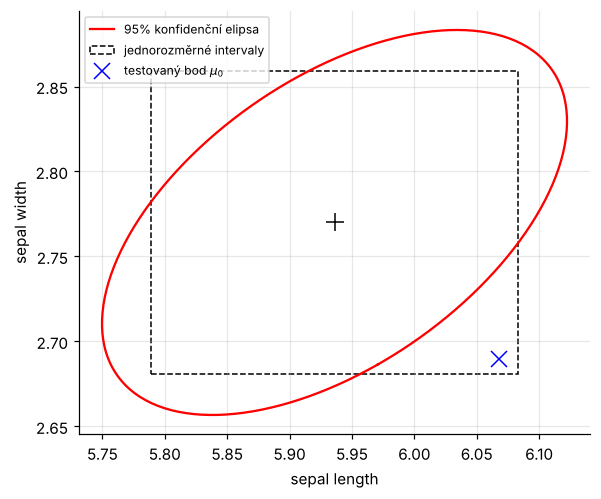

Hotelling pro testovaný bod: p = 0.0026
t-testy: p = [np.float64(0.077), np.float64(0.077)]


In [13]:
X2 = Xv[:, :2]                                 # sepal length, sepal width
n, k = X2.shape
xbar, S = X2.mean(axis=0), np.cov(X2, rowvar=False)
c2 = (n - 1) * k / (n - k) * stats.f.ppf(0.95, k, n - k) / n
vals, vecs = np.linalg.eigh(S)
phi = np.linspace(0, 2 * np.pi, 300)
ell = xbar + (np.c_[np.cos(phi), np.sin(phi)] * np.sqrt(vals * c2)) @ vecs.T

tq = stats.t.ppf(0.975, n - 1)
half = tq * np.sqrt(np.diag(S) / n)            # jednorozmerne intervaly
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(ell[:, 0], ell[:, 1], 'r', label='95% konfidenční elipsa')
ax.add_patch(plt.Rectangle(xbar - half, 2 * half[0], 2 * half[1], fill=False, ls='--', label='jednorozměrné intervaly'))
ax.plot(*xbar, 'k+', ms=12)
test_pt = xbar + np.array([0.9, -0.9]) * half  # bod "proti" korelaci
ax.plot(*test_pt, 'bx', ms=10, label='testovaný bod $\\mu_0$')
ax.set_xlabel('sepal length'); ax.set_ylabel('sepal width'); ax.legend(fontsize=8)
plt.show()
print('Hotelling pro testovaný bod: p = {:.4f}'.format(hotelling_1(X2, test_pt)[2]))
print('t-testy: p =', [round(stats.ttest_1samp(X2[:, j], test_pt[j]).pvalue, 3) for j in range(2)])

## 4.2 Známá $\Sigma$ a test poměrem věrohodností

* Při známé $\Sigma$: $\chi^2=n(\bar{\mathbf x}-\boldsymbol\mu_0)^T\Sigma^{-1}(\bar{\mathbf x}-\boldsymbol\mu_0)\sim\chi^2_k$.
* Test poměrem věrohodností: $-2\ln\lambda=n\ln\left(1+\frac{T^2}{n-1}\right)\approx\chi^2_k$.

Simulací porovnáme skutečnou hladinu asymptotického testu s exaktním F-testem pro malé $n$.

In [14]:
B = 4000
rows = []
for n in [10, 20, 50, 200]:
    r_F = r_LR = 0
    for _ in range(B):
        X = RNG.standard_normal((n, 4))
        T2, F, p = hotelling_1(X, np.zeros(4))
        LR = n * np.log(1 + T2 / (n - 1))
        r_F += p < 0.05
        r_LR += stats.chi2.sf(LR, 4) < 0.05
    rows.append({'n': n, 'exaktní F-test': r_F / B, 'asymptotický LR test': r_LR / B})
display(pd.DataFrame(rows).set_index('n').round(3))

,exaktní F-test,asymptotický LR test
n,,
10,0.044,0.153
20,0.050,0.085
50,0.052,0.064
200,0.050,0.053


Asymptotický test pro malá $n$ zamítá platnou hypotézu příliš často; exaktní F-test drží hladinu pro všechna $n$.

## 4.3 Test o varianční matici $H_0:\Sigma=\Sigma_0$

$$-2\ln\lambda=n\,\mathrm{tr}(\Sigma_0^{-1}S_0)-n\ln|\Sigma_0^{-1}S_0|-nk\approx\chi^2_{k(k+1)/2}.$$

In [15]:
def test_sigma(X, Sigma0):
    n, k = X.shape
    S0 = np.cov(X, rowvar=False, ddof=0)
    A = np.linalg.solve(Sigma0, S0)
    LR = n * np.trace(A) - n * np.linalg.slogdet(A)[1] - n * k
    return LR, stats.chi2.sf(LR, k * (k + 1) // 2)

Sigma0 = np.array([[1.0, 0.2, 0.1], [0.2, 1.5, 0.3], [0.1, 0.3, 2.0]])
X_ok = RNG.multivariate_normal(np.zeros(3), Sigma0, 100)
X_bad = RNG.multivariate_normal(np.zeros(3), 1.5 * Sigma0, 100)
print('data s Sigma0:     LR = {:.2f}, p = {:.4f}'.format(*test_sigma(X_ok, Sigma0)))
print('data s 1.5*Sigma0: LR = {:.2f}, p = {:.4f}'.format(*test_sigma(X_bad, Sigma0)))

data s Sigma0:     LR = 6.93, p = 0.3272
data s 1.5*Sigma0: LR = 34.68, p = 0.0000


---
# 5. Vícerozměrná data – dva výběry

## 5.1 Dvouvýběrový Hotellingův $T^2$ test (shodná neznámá $\Sigma$)

Porovnáme druhy *versicolor* a *virginica* ve všech čtyřech proměnných.
$$T^2=\frac{n_1n_2}{n_1+n_2}(\bar{\mathbf x}_1-\bar{\mathbf x}_2)^TS_p^{-1}(\bar{\mathbf x}_1-\bar{\mathbf x}_2),\qquad
F=\frac{n_1+n_2-k-1}{k(n_1+n_2-2)}T^2\sim F_{k,n_1+n_2-k-1}.$$

In [16]:
def hotelling_2(X1, X2):
    n1, k = X1.shape
    n2 = len(X2)
    Sp = ((n1 - 1) * np.atleast_2d(np.cov(X1, rowvar=False))
          + (n2 - 1) * np.atleast_2d(np.cov(X2, rowvar=False))) / (n1 + n2 - 2)
    d = X1.mean(axis=0) - X2.mean(axis=0)
    T2 = n1 * n2 / (n1 + n2) * d @ np.linalg.solve(Sp, d)
    F = (n1 + n2 - k - 1) / (k * (n1 + n2 - 2)) * T2
    return T2, F, stats.f.sf(F, k, n1 + n2 - k - 1)


def hotelling_2_unequal(X1, X2):
    n1, k = X1.shape
    n2 = len(X2)
    d = X1.mean(axis=0) - X2.mean(axis=0)
    V = np.cov(X1, rowvar=False) / n1 + np.cov(X2, rowvar=False) / n2
    T2 = d @ np.linalg.solve(V, d)
    return T2, stats.chi2.sf(T2, k)

X1, X2 = X_iris[y_iris == 1], X_iris[y_iris == 2]
print('shodná Sigma:  T2 = {:.2f}, F = {:.2f}, p = {:.3g}'.format(*hotelling_2(X1, X2)))
print('různé Sigma:   T2 = {:.2f}, p = {:.3g}'.format(*hotelling_2_unequal(X1, X2)))
print('pro k = 1 splývá s t-testem: Hotelling p = {:.4f}, t-test p = {:.4f}'.format(
    hotelling_2(X1[:, [1]], X2[:, [1]])[2], stats.ttest_ind(X1[:, 1], X2[:, 1]).pvalue))

shodná Sigma:  T2 = 355.47, F = 86.15, p = 9.54e-31
různé Sigma:   T2 = 355.47, p = 1.15e-75
pro k = 1 splývá s t-testem: Hotelling p = 0.0018, t-test p = 0.0018


### Příklad, kdy jednotlivé t-testy nic nenajdou, ale Hotellingův test ano

Dvě silně korelované proměnné, posun skupin je „kolmo“ na hlavní osu korelace.

t-testy: p = [np.float64(0.132), np.float64(0.338)]
Hotelling: p = 3.6e-06


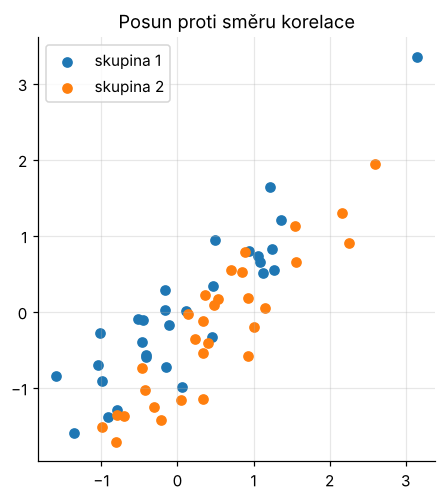

In [17]:
Sig = np.array([[1, 0.9], [0.9, 1]])
A = RNG.multivariate_normal([0, 0], Sig, 30)
Bm = RNG.multivariate_normal([0.35, -0.35], Sig, 30)
print('t-testy: p =', [round(stats.ttest_ind(A[:, j], Bm[:, j]).pvalue, 3) for j in range(2)])
print('Hotelling: p = {:.2g}'.format(hotelling_2(A, Bm)[2]))

plt.figure(figsize=(5, 5))
plt.scatter(*A.T, label='skupina 1'); plt.scatter(*Bm.T, label='skupina 2')
plt.gca().set_aspect('equal'); plt.legend(); plt.title('Posun proti směru korelace')
plt.show()

## 5.2 Test shody variančních matic (Boxův M-test)

Předpokladem dvouvýběrového Hotellingova testu (a MANOVA v P07) je shoda variančních matic. Boxův M-test
je testem poměrem věrohodností s korekcí pro malé výběry; pro $g$ skupin
$$M=(n-g)\ln|S_p|-\sum_j(n_j-1)\ln|S_j|,\qquad (1-c)\,M\approx\chi^2_{(g-1)k(k+1)/2},$$
$$c=\frac{2k^2+3k-1}{6(k+1)(g-1)}\left(\sum_j\frac1{n_j-1}-\frac1{n-g}\right).$$

In [18]:
def box_m(*groups):
    g = len(groups)
    k = groups[0].shape[1]
    ns = np.array([len(x) for x in groups])
    n = ns.sum()
    Ss = [np.cov(x, rowvar=False) for x in groups]
    Sp = sum((nj - 1) * Sj for nj, Sj in zip(ns, Ss)) / (n - g)
    M = (n - g) * np.linalg.slogdet(Sp)[1] - sum((nj - 1) * np.linalg.slogdet(Sj)[1] for nj, Sj in zip(ns, Ss))
    c = (2 * k**2 + 3 * k - 1) / (6 * (k + 1) * (g - 1)) * (np.sum(1 / (ns - 1)) - 1 / (n - g))
    stat = (1 - c) * M
    df = (g - 1) * k * (k + 1) / 2
    return M, stat, stats.chi2.sf(stat, df)

print('versicolor vs virginica: M = {:.2f}, chi2 = {:.2f}, p = {:.3g}'.format(*box_m(X1, X2)))
print('všechny 3 druhy:         M = {:.2f}, chi2 = {:.2f}, p = {:.3g}'.format(*box_m(*[X_iris[y_iris == j] for j in range(3)])))

versicolor vs virginica: M = 36.64, chi2 = 35.04, p = 0.000123
všechny 3 druhy:         M = 146.66, chi2 = 140.94, p = 3.35e-20


Varianční matice druhů Iris se liší, proto je u dvouvýběrového testu bezpečnější varianta pro různé $\Sigma_1,\Sigma_2$.
Při **stejných rozsazích** $n_1=n_2$ mají obě varianty stejnou hodnotu $T^2$ (liší se jen referenčním rozdělením F vs. $\chi^2$); rozdíl se projeví až při nestejných rozsazích. Rozdíl středních hodnot je zde navíc tak velký, že závěr je stejný. Boxův M-test je ale velmi citlivý na
odchylky od normality, a zamítá proto často.

---
# 6. Shrnutí – jak vybrat test

| Situace | Normální data | Bez předpokladu normality |
|---|---|---|
| jeden výběr, $H_0:\mu=\mu_0$ | t-test (z-test při známém $\sigma$) | Wilcoxonův test (symetrie), znaménkový test |
| dva nezávislé výběry | Welchův test (t-test při shodných rozptylech) | Mann-Whitneyův, Brunnerův-Munzelův, permutační test |
| párová data | párový t-test | Wilcoxonův test na rozdílech |
| shoda rozptylů | F-test | Brown-Forsytheův (Leveneův) test |
| vícerozměrná data, jeden výběr | Hotellingův $T^2$ (F-verze) | permutační / bootstrap verze |
| vícerozměrná data, dva výběry | Hotellingův $T^2$, pro různé $\Sigma$ varianta s $S_1/n_1+S_2/n_2$ | permutační test |
| shoda variančních matic | Boxův M-test | – |

## Úlohy

1. Simulací ověřte, že dvouvýběrový Hotellingův test drží hladinu pro $k=4$, $n_1=n_2=15$.
2. Pro data Iris (*setosa*) otestujte $H_0:\boldsymbol\mu=(5{,}0;\,3{,}4;\,1{,}5;\,0{,}25)^T$ a porovnejte s výsledky čtyř t-testů s Bonferroniho korekcí.
3. Simulací porovnejte sílu Mann-Whitneyova a Welchova testu pro posunutá exponenciální rozdělení.
4. Implementujte permutační verzi dvouvýběrového Hotellingova testu (náhodné přeřazení řádků mezi skupinami) a porovnejte p-hodnotu s F-verzí.